In [1]:
# Energy Consumption Forecasting Using Machine Learning

#Objective:
#Predict household electricity consumption using historical energy data.

#Models:
#1. Random Forest Regressor
#2. XGBoost Regressor

In [76]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error

)

import joblib
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

In [3]:
#===========================
#   READ DATA
#===========================
df = pd.read_csv(
    "D:\IST\Energy Consumption Forecasting\Dataset/household_power_consumption.txt",
    sep=";",
    low_memory=False
)
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(8)
memory usage: 142.5+ MB


In [5]:
df.isnull().sum()

Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64

In [6]:
#==================================
#         DATA CLEANING
#==================================
(df == "?").sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
# Replace ? with NaN
df.replace("?", np.nan, inplace=True)

In [9]:
df.isnull().sum()

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

In [10]:
df.dropna(inplace=True)

In [11]:
df.isnull().sum()

Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

In [12]:
df.shape

(2049280, 9)

In [13]:
numeric_columns=[
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2049280 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 156.3+ MB


In [15]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

In [16]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00


In [17]:
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["Minute"] = df["Datetime"].dt.minute
df["Weekday"] = df["Datetime"].dt.day_name()

In [18]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime,Year,Month,Day,Hour,Minute,Weekday
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00,2006,12,16,17,24,Saturday
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00,2006,12,16,17,25,Saturday
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00,2006,12,16,17,26,Saturday
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00,2006,12,16,17,27,Saturday
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00,2006,12,16,17,28,Saturday


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2049280 entries, 0 to 2075258
Data columns (total 16 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   Date                   object        
 1   Time                   object        
 2   Global_active_power    float64       
 3   Global_reactive_power  float64       
 4   Voltage                float64       
 5   Global_intensity       float64       
 6   Sub_metering_1         float64       
 7   Sub_metering_2         float64       
 8   Sub_metering_3         float64       
 9   Datetime               datetime64[ns]
 10  Year                   int32         
 11  Month                  int32         
 12  Day                    int32         
 13  Hour                   int32         
 14  Minute                 int32         
 15  Weekday                object        
dtypes: datetime64[ns](1), float64(7), int32(5), object(3)
memory usage: 226.7+ MB


In [20]:
(df["Global_active_power"] < 0).sum()

np.int64(0)

In [21]:
(df["Voltage"] < 0).sum()

np.int64(0)

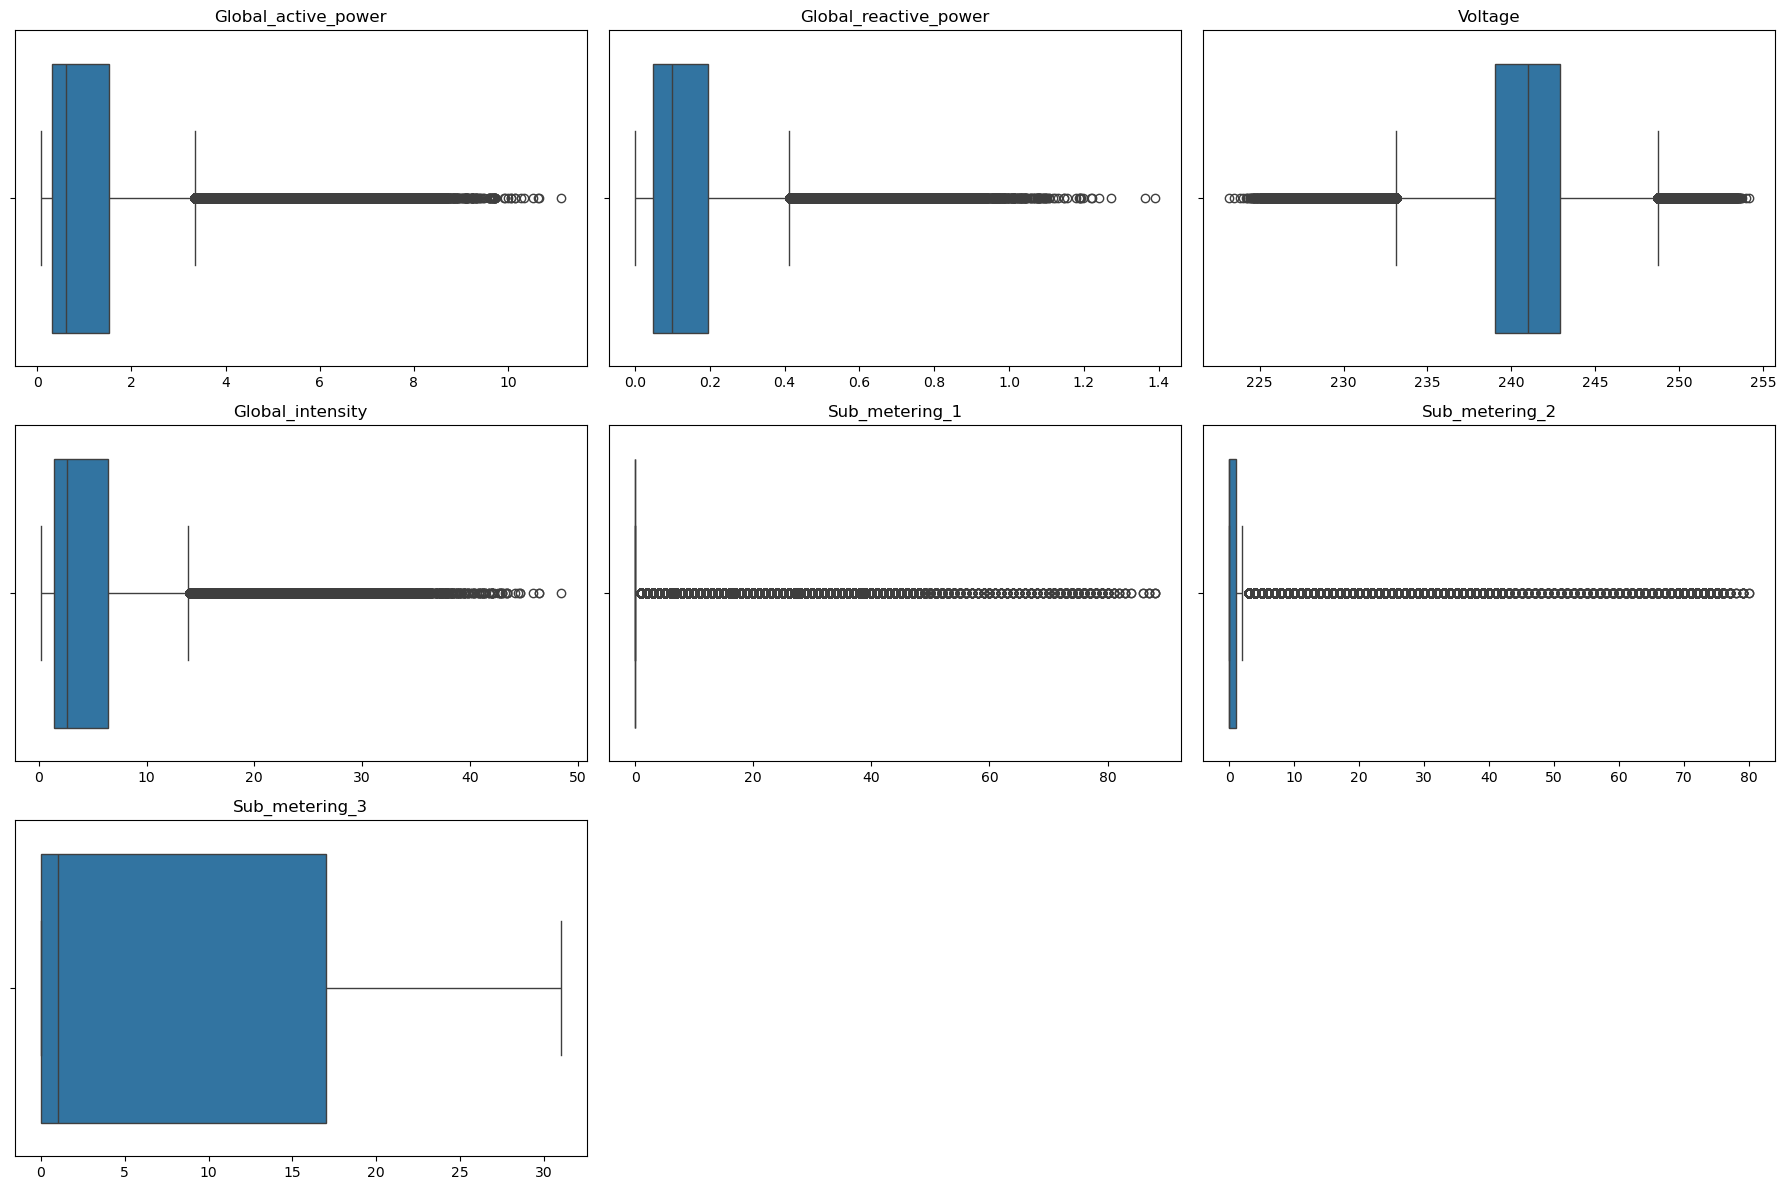

In [22]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18,12))
axes = axes.flatten()
for i, col in enumerate(numeric_columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
# Extra subplot remove
for j in range(len(numeric_columns), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()

plt.show()

In [23]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    print(f"{column}")
    print(f"Outliers: {len(outliers)}")
    print("-"*40)

for col in numeric_columns:
    detect_outliers_iqr(df, col)

Global_active_power
Outliers: 94907
----------------------------------------
Global_reactive_power
Outliers: 40420
----------------------------------------
Voltage
Outliers: 51067
----------------------------------------
Global_intensity
Outliers: 100961
----------------------------------------
Sub_metering_1
Outliers: 169105
----------------------------------------
Sub_metering_2
Outliers: 77151
----------------------------------------
Sub_metering_3
Outliers: 0
----------------------------------------


In [24]:
def outlier_percentage(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    percentage = (len(outliers)/len(data))*100
    print(f"{column}: {percentage:.2f}%")

for col in numeric_columns:
    outlier_percentage(df,col)

Global_active_power: 4.63%
Global_reactive_power: 1.97%
Voltage: 2.49%
Global_intensity: 4.93%
Sub_metering_1: 8.25%
Sub_metering_2: 3.76%
Sub_metering_3: 0.00%


In [25]:
def cap_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    data[column] = data[column].clip(lower=lower, upper=upper)

    return data

df_capped = df.copy()
for col in numeric_columns:
    df_capped = cap_outliers_iqr(df_capped, col)

In [26]:
for col in numeric_columns:
    outlier_percentage(df_capped, col)

Global_active_power: 0.00%
Global_reactive_power: 0.00%
Voltage: 0.00%
Global_intensity: 0.00%
Sub_metering_1: 0.00%
Sub_metering_2: 0.00%
Sub_metering_3: 0.00%


In [27]:
#Outlier Detection: Boxplots and the IQR method were used to identify potential outliers. Since the dataset represents real 
#household electricity usage, extreme values may correspond to genuine high-consumption events rather than data errors. 
#Therefore, no outlier removal was performed to preserve real-world patterns.

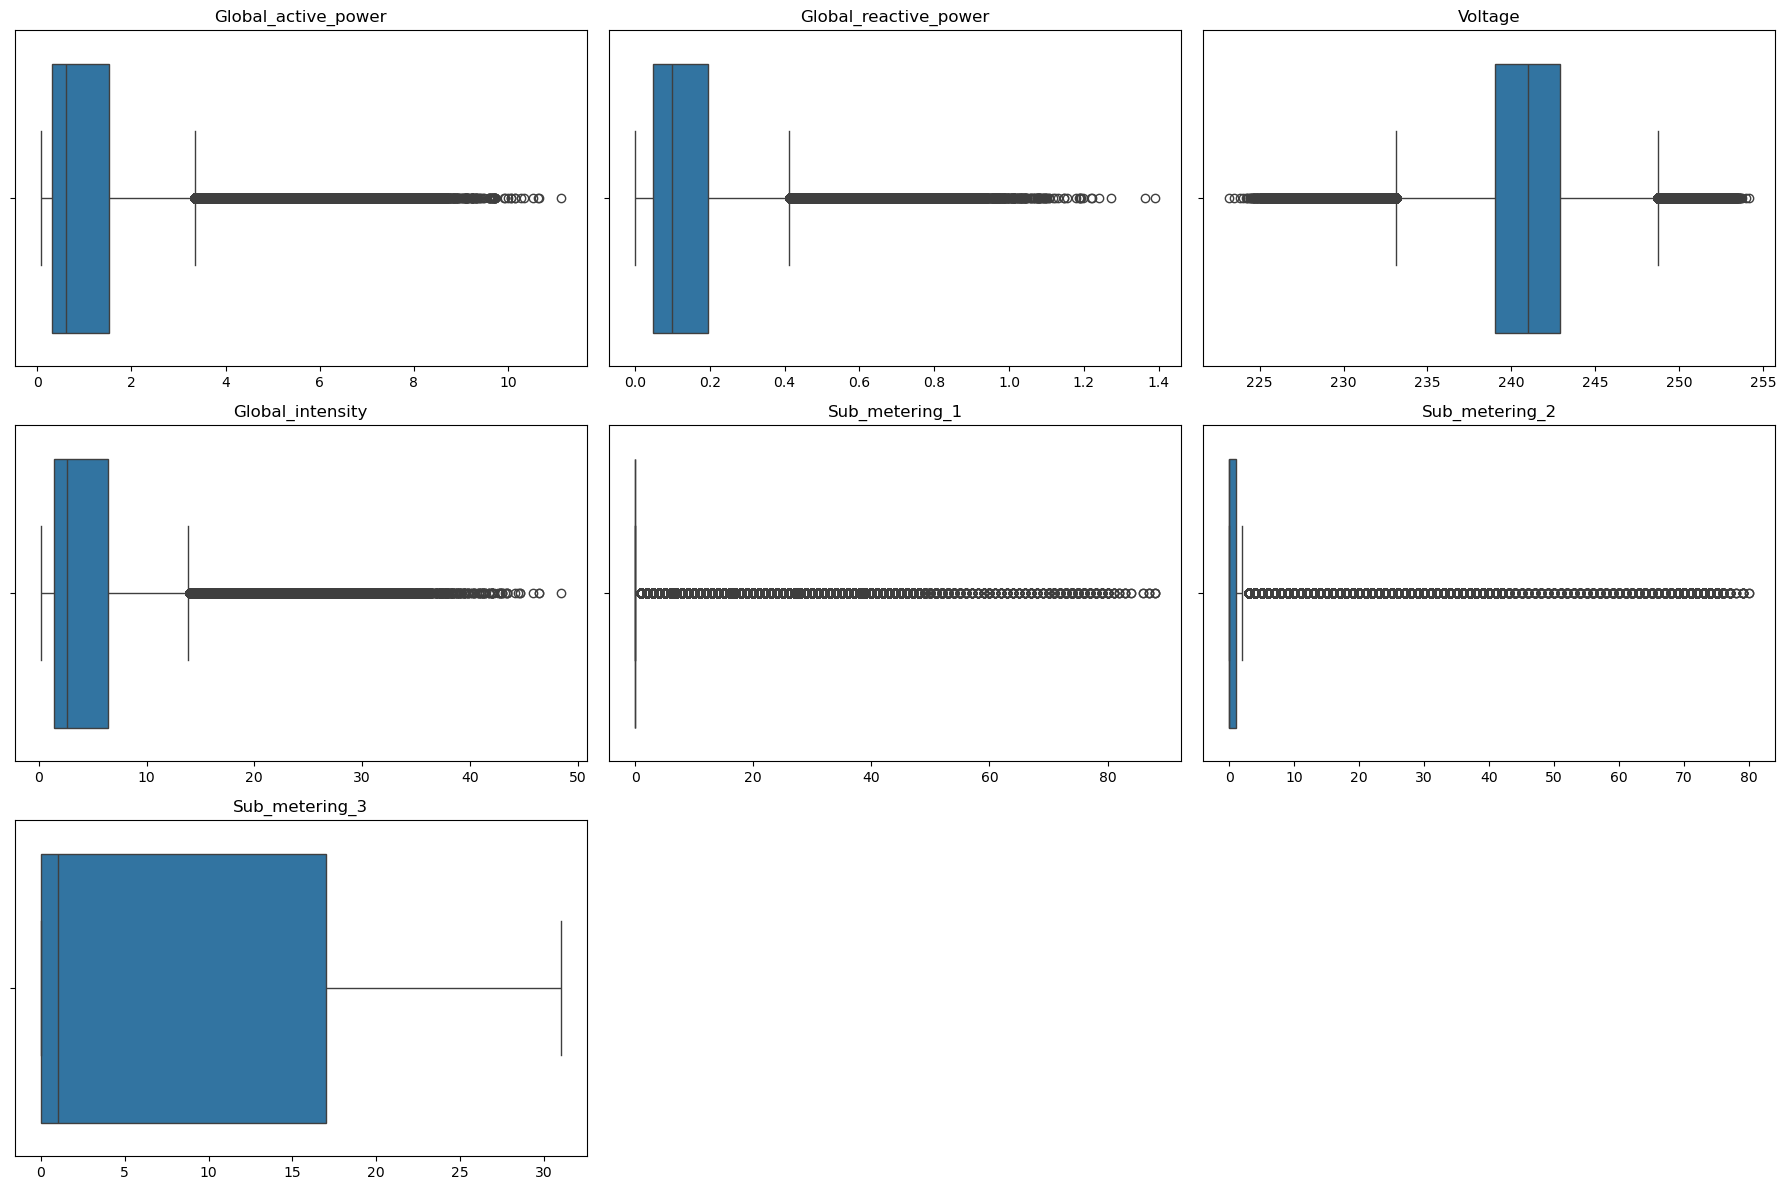

In [28]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18,12))
axes = axes.flatten()
for i, col in enumerate(numeric_columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
# Extra subplot remove
for j in range(len(numeric_columns), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()

plt.show()

In [29]:
df_capped = df.copy()
print(df["Global_active_power"].max())
print(df_capped["Global_active_power"].max())

11.122
11.122


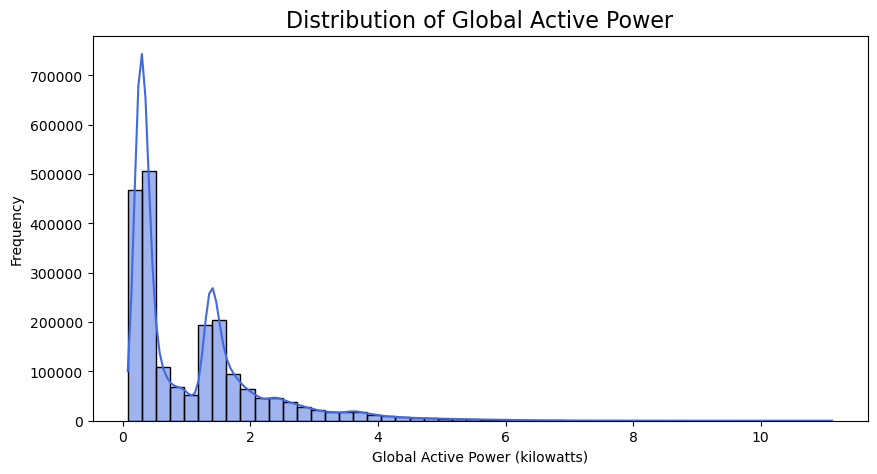

In [30]:
plt.figure(figsize=(10,5))
sns.histplot(
    data=df,
    x="Global_active_power",
    bins=50,
    kde=True,
    color="royalblue"
)

plt.title("Distribution of Global Active Power", fontsize=16)
plt.xlabel("Global Active Power (kilowatts)")
plt.ylabel("Frequency")

plt.show()

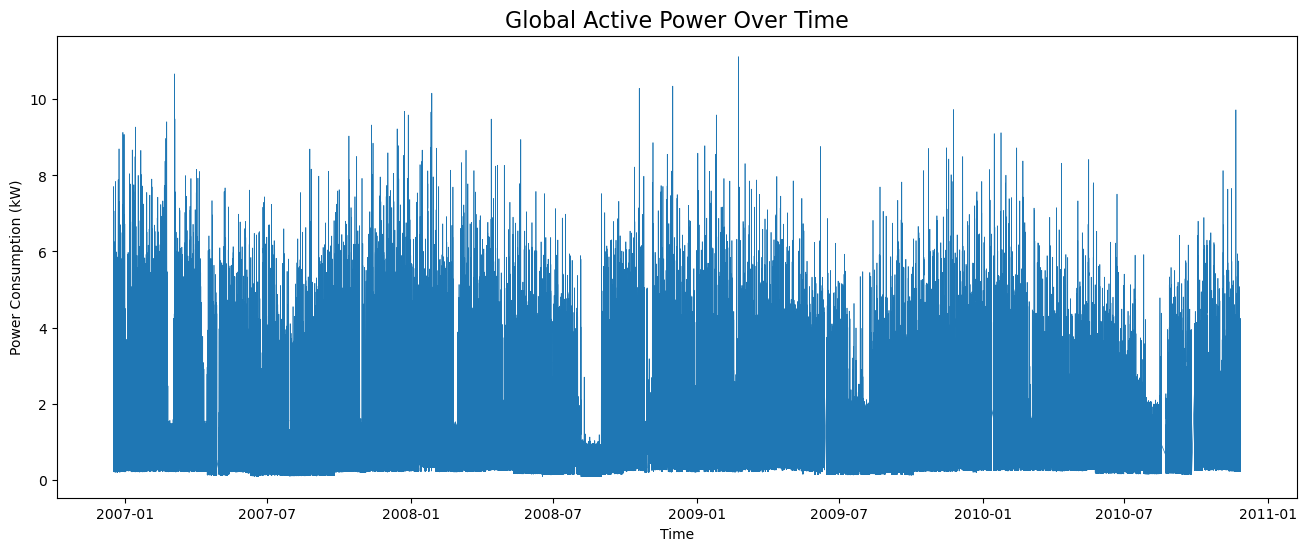

In [31]:
plt.figure(figsize=(16,6))
plt.plot(
    df["Datetime"],
    df["Global_active_power"],
    linewidth=0.5
)
plt.title("Global Active Power Over Time", fontsize=16)
plt.xlabel("Time")
plt.ylabel("Power Consumption (kW)")
plt.show()

In [32]:
daily_power = (
    df.set_index("Datetime")
      .resample("D")["Global_active_power"]
      .mean()
)

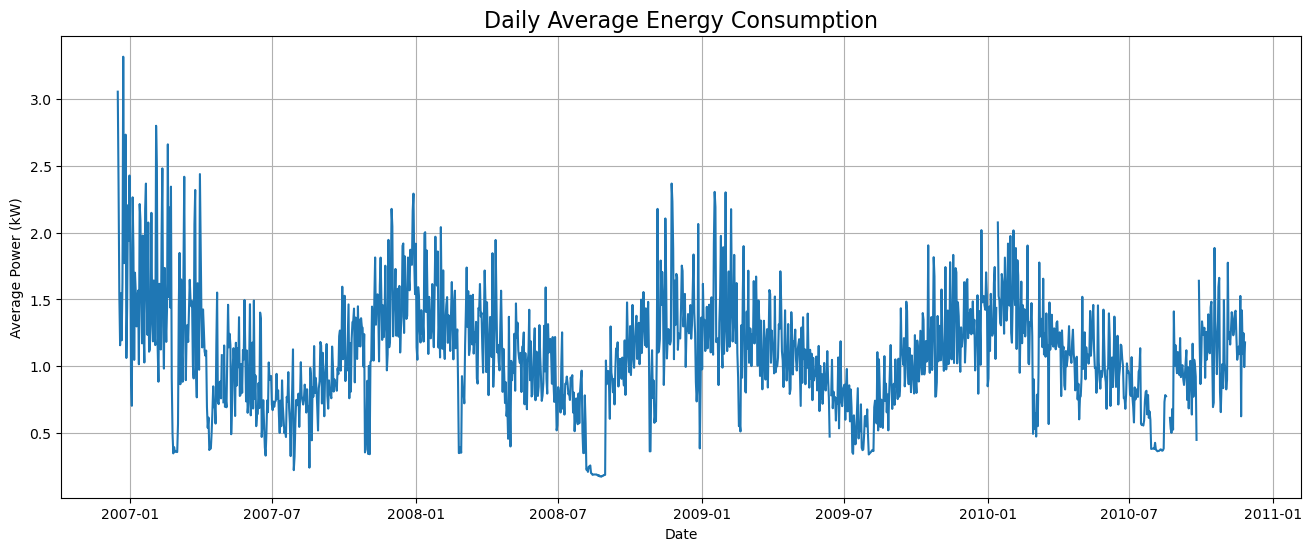

In [33]:
plt.figure(figsize=(16,6))
plt.plot(daily_power)
plt.title("Daily Average Energy Consumption", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Average Power (kW)")
plt.grid(True)
plt.show()

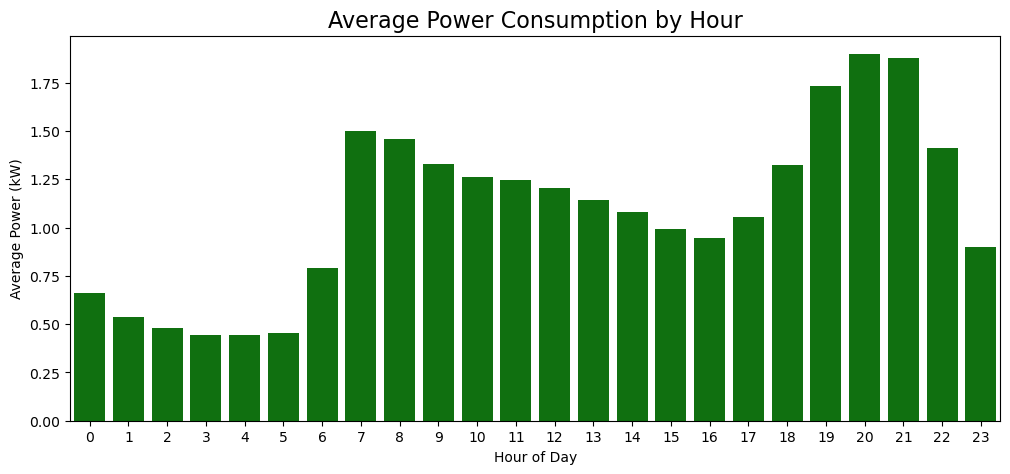

In [34]:
plt.figure(figsize=(12,5))
sns.barplot(
    data=df,
    x="Hour",
    y="Global_active_power",
    estimator="mean",
    errorbar=None,
    color="green"
)

plt.title("Average Power Consumption by Hour", fontsize=16)
plt.xlabel("Hour of Day")
plt.ylabel("Average Power (kW)")

plt.show()

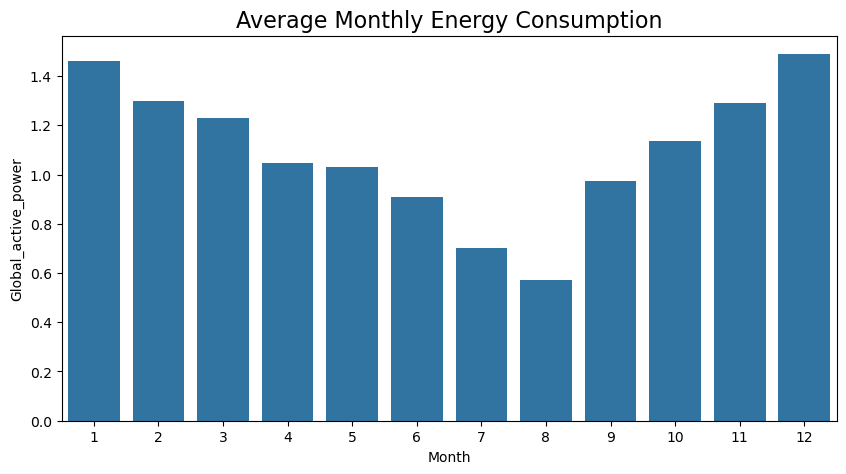

In [35]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="Month",
    y="Global_active_power",
    estimator="mean",
    errorbar=None
)

plt.title("Average Monthly Energy Consumption", fontsize=16)

plt.show()

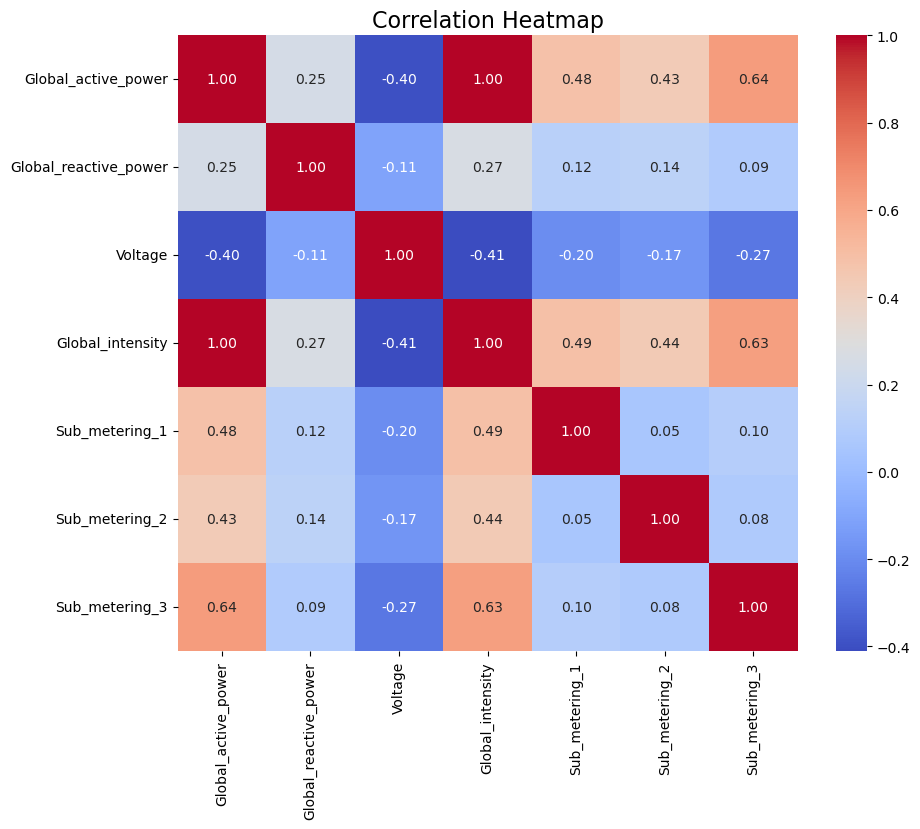

In [36]:
plt.figure(figsize=(10,8))

correlation = df[numeric_columns].corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap", fontsize=16)

plt.show()

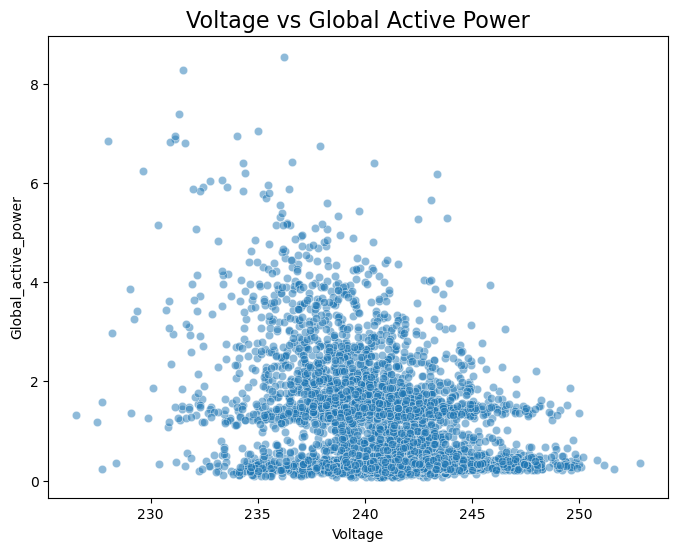

In [37]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df.sample(5000, random_state=42),
    x="Voltage",
    y="Global_active_power",
    alpha=0.5
)
plt.title("Voltage vs Global Active Power", fontsize=16)

plt.show()

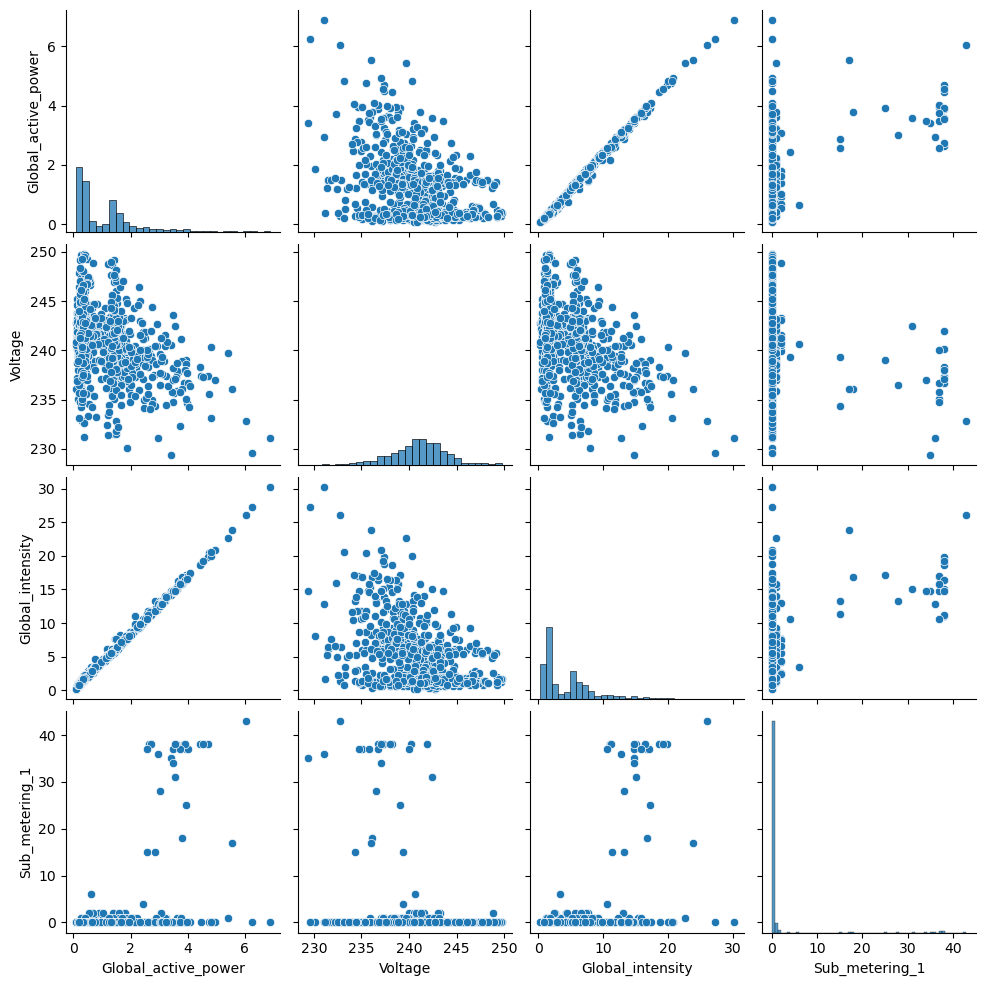

In [38]:
sample_df = df.sample(1000, random_state=42)
sns.pairplot(
    sample_df[
        [
            "Global_active_power",
            "Voltage",
            "Global_intensity",
            "Sub_metering_1"
        ]
    ]
)

plt.show()

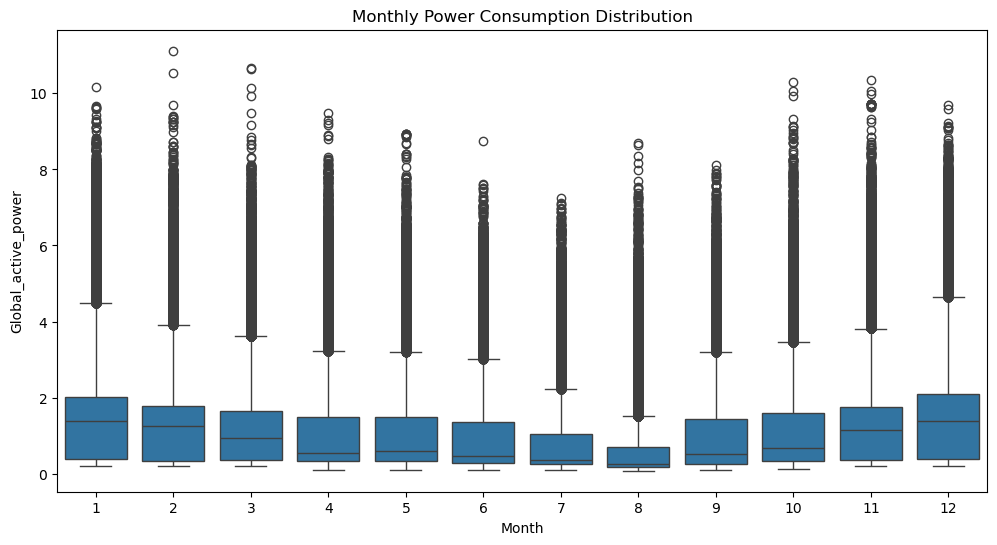

In [39]:
plt.figure(figsize=(12,6))
sns.boxplot(
    data=df,
    x="Month",
    y="Global_active_power"
)
plt.title("Monthly Power Consumption Distribution")

plt.show()

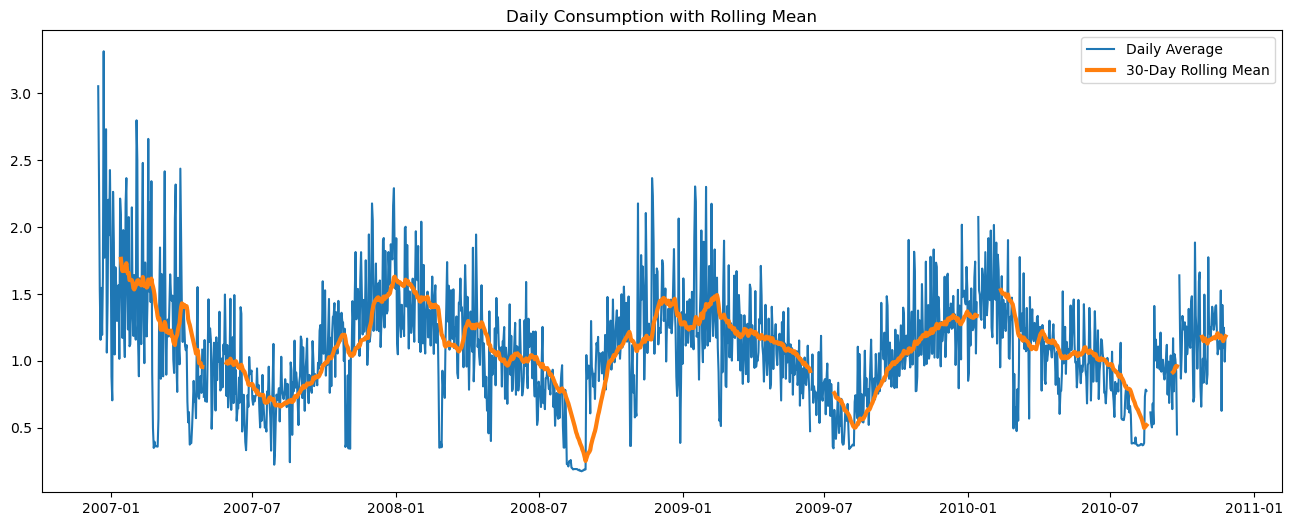

In [40]:
daily_power = (
    df.set_index("Datetime")
      .resample("D")["Global_active_power"]
      .mean()
)
rolling = daily_power.rolling(30).mean()
plt.figure(figsize=(16,6))
plt.plot(daily_power, label="Daily Average")
plt.plot(rolling, linewidth=3, label="30-Day Rolling Mean")
plt.legend()
plt.title("Daily Consumption with Rolling Mean")
plt.show()

In [41]:
#......................FEATURE  ENGINEERING........................

df["Is_Weekend"] = df["Datetime"].dt.dayofweek >= 5
df["Is_Weekend"] = df["Is_Weekend"].astype(int)

In [42]:
df["Peak_Hour"] = (
    (df["Hour"] >= 18) &
    (df["Hour"] <= 22)
).astype(int)

In [43]:
def get_time_period(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 22:
        return "Evening"
    else:
        return "Night"
df["Time_Period"] = df["Hour"].apply(get_time_period)
df[["Hour","Time_Period"]].tail(3)

,Hour,Time_Period
2075256,21,Evening
2075257,21,Evening
2075258,21,Evening


In [44]:
# ==========================================
# ROLLING FEATURES
# ==========================================

df["Rolling_Mean_60"] = (
    df["Global_active_power"]
      .rolling(60)
      .mean()
      .shift(1)
)


df["Rolling_STD_60"] = (
    df["Global_active_power"]
      .rolling(60)
      .std()
      .shift(1)
)
df.dropna(inplace=True)


df["Rolling_Max_60"] = (
    df["Global_active_power"]
      .rolling(window=60)
      .max()
      .shift(1)
)

df["Rolling_Min_60"] = (
    df["Global_active_power"]
      .rolling(window=60)
      .min()
      .shift(1)
)
df = df.loc[:, ~df.columns.duplicated()]

In [45]:
# ==========================================
# LAG FEATURES
# ==========================================

# Previous 1 Minute
df["Lag_1"] = df["Global_active_power"].shift(1)
# Previous 60 Minutes (1 Hour)
df["Lag_60"] = df["Global_active_power"].shift(60)
# Previous 1440 Minutes (1 Day)
df["Lag_1440"] = df["Global_active_power"].shift(1440)
df = df.loc[:, ~df.columns.duplicated()]

In [46]:
# ==========================================
# ONE HOT ENCODING
# ==========================================

df = pd.get_dummies(
    df,
    columns=["Time_Period"],
    drop_first=True,
    dtype=int
)

In [47]:
df = pd.get_dummies(
    df,
    columns=["Weekday"],
    drop_first=True,
    dtype=int
)

In [48]:
# Remove duplicate columns
df = df.loc[:, ~df.columns.duplicated()]

In [49]:
print(df.columns.tolist())

['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Datetime', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'Is_Weekend', 'Peak_Hour', 'Rolling_Mean_60', 'Rolling_STD_60', 'Rolling_Max_60', 'Rolling_Min_60', 'Lag_1', 'Lag_60', 'Lag_1440', 'Time_Period_Evening', 'Time_Period_Morning', 'Time_Period_Night', 'Weekday_Monday', 'Weekday_Saturday', 'Weekday_Sunday', 'Weekday_Thursday', 'Weekday_Tuesday', 'Weekday_Wednesday']


In [50]:
# TARGET VARIABLE
target = "Global_active_power"

In [51]:
# ==========================================
# REMOVE UNNECESSARY COLUMNS
# ==========================================

drop_columns = [
    "Date",
    "Time",
    "Datetime",
    "Global_active_power",
    "Global_intensity"
]

X = df.drop(columns=drop_columns)
y = df["Global_active_power"]

In [52]:
print("="*60)
print("FINAL FEATURE LIST")
print("="*60)

print(X.columns.tolist())
print("\n")

print("Total Features :", X.shape[1])
print("Total Samples :", X.shape[0])

FINAL FEATURE LIST
['Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'Year', 'Month', 'Day', 'Hour', 'Minute', 'Is_Weekend', 'Peak_Hour', 'Rolling_Mean_60', 'Rolling_STD_60', 'Rolling_Max_60', 'Rolling_Min_60', 'Lag_1', 'Lag_60', 'Lag_1440', 'Time_Period_Evening', 'Time_Period_Morning', 'Time_Period_Night', 'Weekday_Monday', 'Weekday_Saturday', 'Weekday_Sunday', 'Weekday_Thursday', 'Weekday_Tuesday', 'Weekday_Wednesday']


Total Features : 28
Total Samples : 2049220


In [53]:
# Remove rows containing NaN values
df.dropna(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)
print(df.isnull().sum().sort_values(ascending=False).head(10))
print("Total Missing Values:", df.isnull().sum().sum())

Date                   0
Rolling_Mean_60        0
Weekday_Tuesday        0
Weekday_Thursday       0
Weekday_Sunday         0
Weekday_Saturday       0
Weekday_Monday         0
Time_Period_Night      0
Time_Period_Morning    0
Time_Period_Evening    0
dtype: int64
Total Missing Values: 0


In [54]:
# ==========================================
# TIME SERIES TRAIN TEST SPLIT
# ==========================================

split_index = int(len(df) * 0.80)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("="*60)
print("TRAIN TEST SPLIT")
print("="*60)
print("Training Samples :", len(X_train))
print("Testing Samples :", len(X_test))
print()
print("Training Shape :", X_train.shape)
print("Testing Shape :", X_test.shape)

TRAIN TEST SPLIT
Training Samples : 1638224
Testing Samples : 410996

Training Shape : (1638224, 28)
Testing Shape : (410996, 28)


In [55]:
# ==========================================
# RANDOM FOREST BASELINE MODEL
# ==========================================

rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

In [56]:
# ==========================================
# TRAIN MODEL
# ==========================================

start_time = time.time()
rf_model.fit(X_train, y_train)
training_time = time.time() - start_time
print(f"Training Time : {training_time:.2f} seconds")

Training Time : 549.29 seconds


In [57]:
# ==========================================
# MAKE PREDICTIONS
# ==========================================

start_time = time.time()
rf_predictions = rf_model.predict(X_test)
prediction_time = time.time() - start_time
print(f"Prediction Time : {prediction_time:.2f} seconds")

Prediction Time : 0.95 seconds


In [58]:
# ==========================================
# MODEL EVALUATION
# ==========================================

mae = mean_absolute_error(y_test, rf_predictions)
mse = mean_squared_error(y_test, rf_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, rf_predictions)
mape = mean_absolute_percentage_error(y_test, rf_predictions)
print("="*70)
print("RANDOM FOREST PERFORMANCE")
print("="*70)
print(f"MAE               : {mae:.4f}")
print(f"MSE               : {mse:.4f}")
print(f"RMSE              : {rmse:.4f}")
print(f"R² Score          : {r2:.4f}")
print(f"MAPE              : {mape:.4f}")
print()
print(f"Training Time     : {training_time:.2f} sec")
print(f"Prediction Time   : {prediction_time:.2f} sec")

RANDOM FOREST PERFORMANCE
MAE               : 0.0593
MSE               : 0.0259
RMSE              : 0.1608
R² Score          : 0.9678
MAPE              : 0.0643

Training Time     : 549.29 sec
Prediction Time   : 0.95 sec


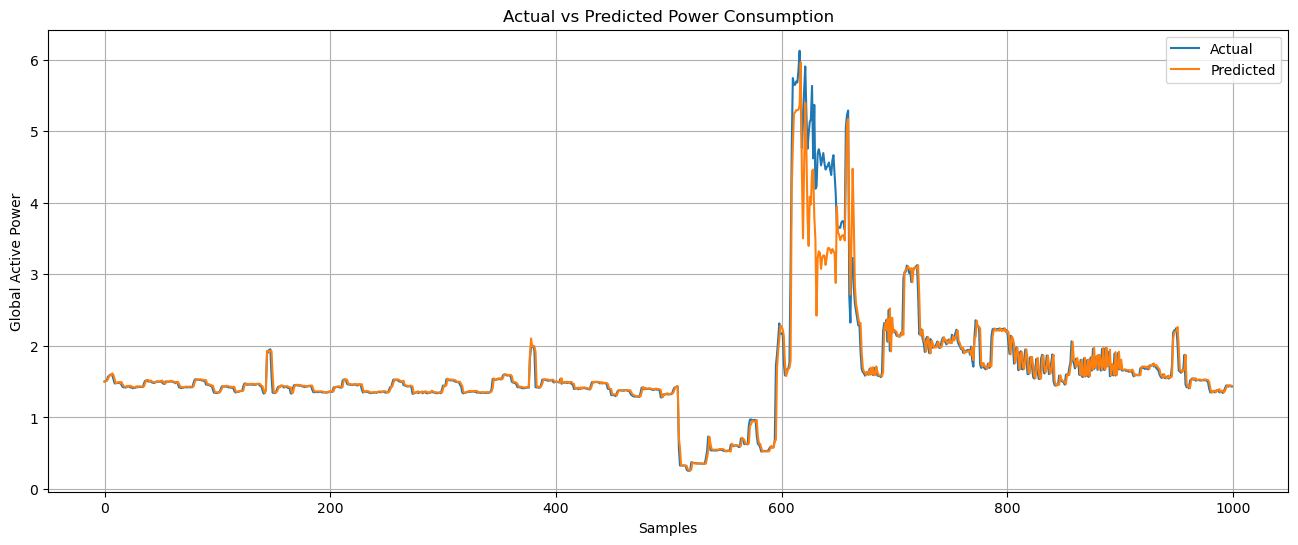

In [59]:
# ==========================================
# ACTUAL VS PREDICTED
# ==========================================

comparison = pd.DataFrame({
    "Actual": y_test.values[:1000],
    "Predicted": rf_predictions[:1000]
})
plt.figure(figsize=(16,6))
plt.plot(comparison["Actual"], label="Actual")
plt.plot(comparison["Predicted"], label="Predicted")
plt.title("Actual vs Predicted Power Consumption")
plt.xlabel("Samples")
plt.ylabel("Global Active Power")
plt.legend()
plt.grid(True)
plt.show()

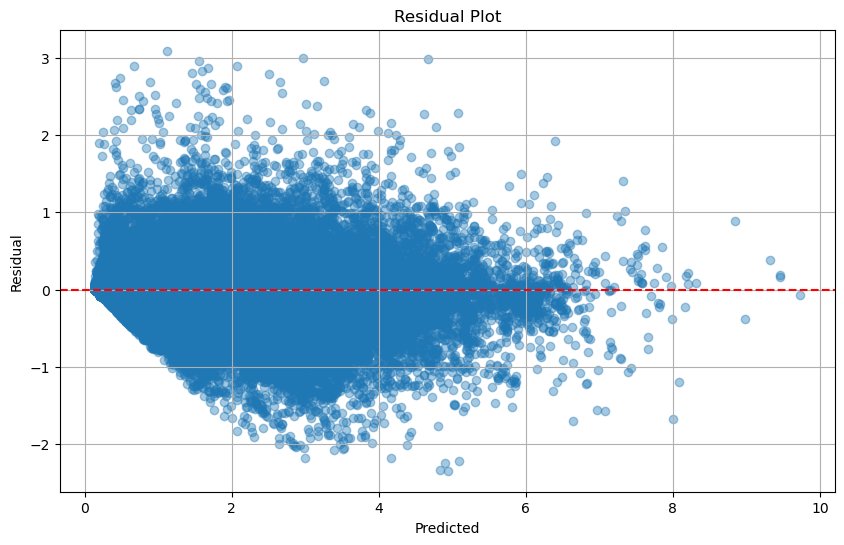

In [60]:
# ==========================================
# RESIDUAL PLOT
# ==========================================

residuals = y_test.values - rf_predictions
plt.figure(figsize=(10,6))
plt.scatter(
    rf_predictions,
    residuals,
    alpha=0.4
)
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(True)
plt.show()

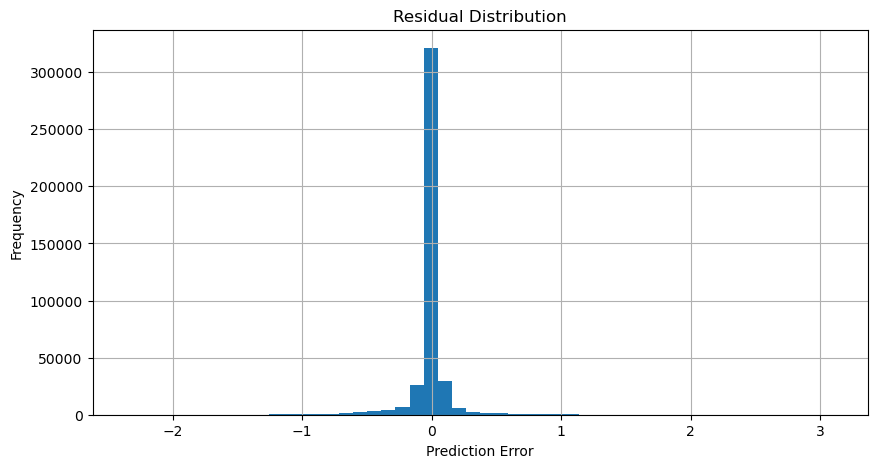

In [61]:
# ==========================================
# ERROR DISTRIBUTION
# ==========================================

plt.figure(figsize=(10,5))
plt.hist(
    residuals,
    bins=50
)
plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [62]:
# ==========================================
# FEATURE IMPORTANCE TABLE
# ==========================================

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})
importance = importance.sort_values(
    by="Importance",
    ascending=False
)
importance.reset_index(drop=True, inplace=True)
display(importance.head(15))

,Feature,Importance
0,Lag_1,0.960851
1,Sub_metering_1,0.011110
2,Sub_metering_2,0.008642
3,Sub_metering_3,0.005730
4,Voltage,0.002502
5,Rolling_Min_60,0.002424
6,Rolling_Mean_60,0.001399
7,Global_reactive_power,0.001248
8,Hour,0.001120
9,Rolling_STD_60,0.001025


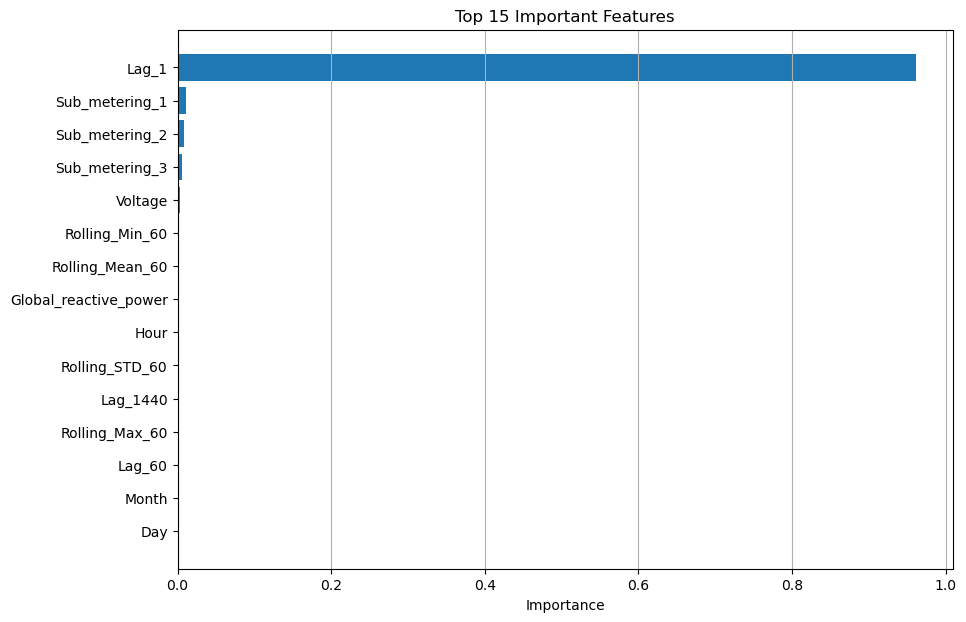

In [63]:
# ==========================================
# TOP 15 IMPORTANT FEATURES
# ==========================================

plt.figure(figsize=(10,7))
plt.barh(
    importance["Feature"][:15],
    importance["Importance"][:15]
)
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Top 15 Important Features")
plt.grid(axis="x")
plt.show()

In [64]:
importance.head(15)

,Feature,Importance
0,Lag_1,0.960851
1,Sub_metering_1,0.011110
2,Sub_metering_2,0.008642
3,Sub_metering_3,0.005730
4,Voltage,0.002502
5,Rolling_Min_60,0.002424
6,Rolling_Mean_60,0.001399
7,Global_reactive_power,0.001248
8,Hour,0.001120
9,Rolling_STD_60,0.001025


In [65]:
# ==========================================
# XGBOOST REGRESSOR
# ==========================================

xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [66]:
# ==========================================
# TRAIN XGBOOST MODEL
# ==========================================

start_time = time.time()
xgb_model.fit(
    X_train,
    y_train
)
xgb_training_time = time.time() - start_time
print(f"Training Time : {xgb_training_time:.2f} seconds")

Training Time : 79.72 seconds


In [67]:
# ==========================================
# XGBOOST PREDICTIONS
# ==========================================

start_time = time.time()
xgb_predictions = xgb_model.predict(X_test)
xgb_prediction_time = time.time() - start_time
print(f"Prediction Time : {xgb_prediction_time:.2f} seconds")

Prediction Time : 2.07 seconds


In [68]:
# ==========================================
# XGBOOST PERFORMANCE
# ==========================================

xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)
xgb_mse = mean_squared_error(
    y_test,
    xgb_predictions
)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(
    y_test,
    xgb_predictions
)
xgb_mape = mean_absolute_percentage_error(
    y_test,
    xgb_predictions
)
print("="*70)
print("XGBOOST PERFORMANCE")
print("="*70)
print(f"MAE               : {xgb_mae:.4f}")
print(f"MSE               : {xgb_mse:.4f}")
print(f"RMSE              : {xgb_rmse:.4f}")
print(f"R² Score          : {xgb_r2:.4f}")
print(f"MAPE              : {xgb_mape:.4f}")
print()
print(f"Training Time     : {xgb_training_time:.2f} sec")
print(f"Prediction Time   : {xgb_prediction_time:.2f} sec")

XGBOOST PERFORMANCE
MAE               : 0.0620
MSE               : 0.0225
RMSE              : 0.1499
R² Score          : 0.9721
MAPE              : 0.0672

Training Time     : 79.72 sec
Prediction Time   : 2.07 sec


In [69]:
# ==========================================
# XGBOOST FEATURE IMPORTANCE
# ==========================================

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})
xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)
xgb_importance.reset_index(
    drop=True,
    inplace=True
)
display(xgb_importance.head(15))

,Feature,Importance
0,Lag_1,0.865437
1,Rolling_Mean_60,0.035649
2,Sub_metering_1,0.020147
3,Sub_metering_3,0.019167
4,Sub_metering_2,0.010693
5,Rolling_Max_60,0.006484
6,Rolling_Min_60,0.005498
7,Time_Period_Evening,0.005221
8,Voltage,0.004783
9,Peak_Hour,0.004425


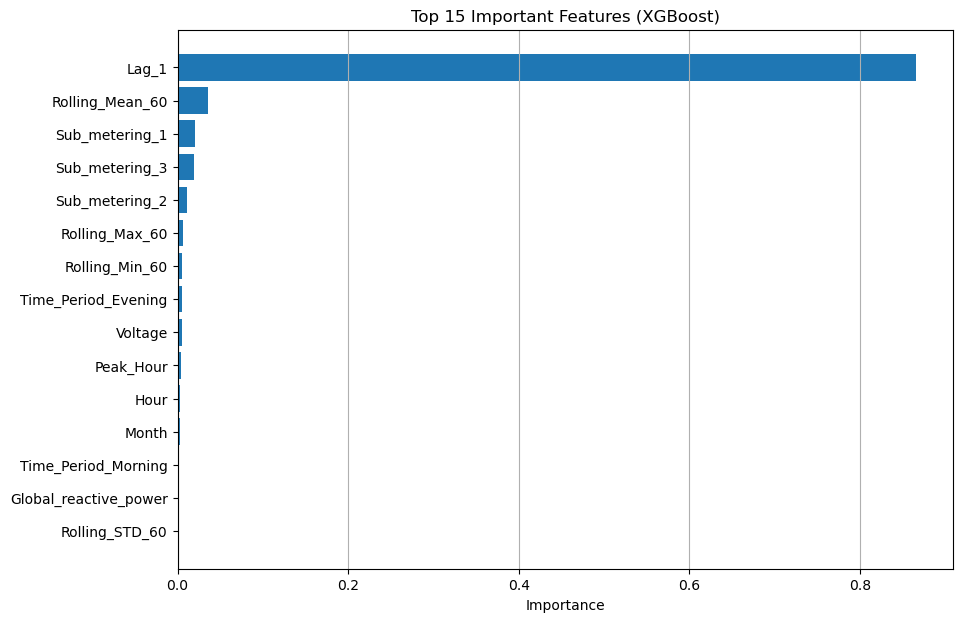

In [70]:
# ==========================================
# TOP FEATURES
# ==========================================

plt.figure(figsize=(10,7))
plt.barh(
    xgb_importance["Feature"][:15],
    xgb_importance["Importance"][:15]
)
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Top 15 Important Features (XGBoost)")
plt.grid(axis="x")
plt.show()

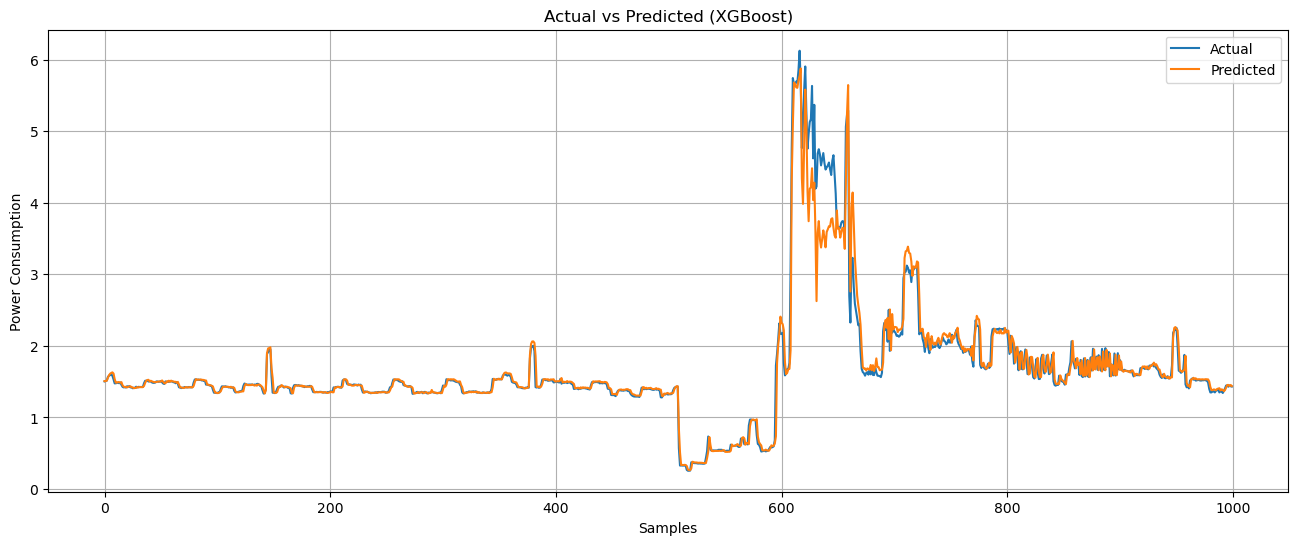

In [71]:
# ==========================================
# ACTUAL VS PREDICTED
# ==========================================

comparison = pd.DataFrame({
    "Actual": y_test.values[:1000],
    "Predicted": xgb_predictions[:1000]
})
plt.figure(figsize=(16,6))
plt.plot(comparison["Actual"], label="Actual")
plt.plot(comparison["Predicted"], label="Predicted")
plt.title("Actual vs Predicted (XGBoost)")
plt.xlabel("Samples")
plt.ylabel("Power Consumption")
plt.legend()
plt.grid(True)
plt.show()

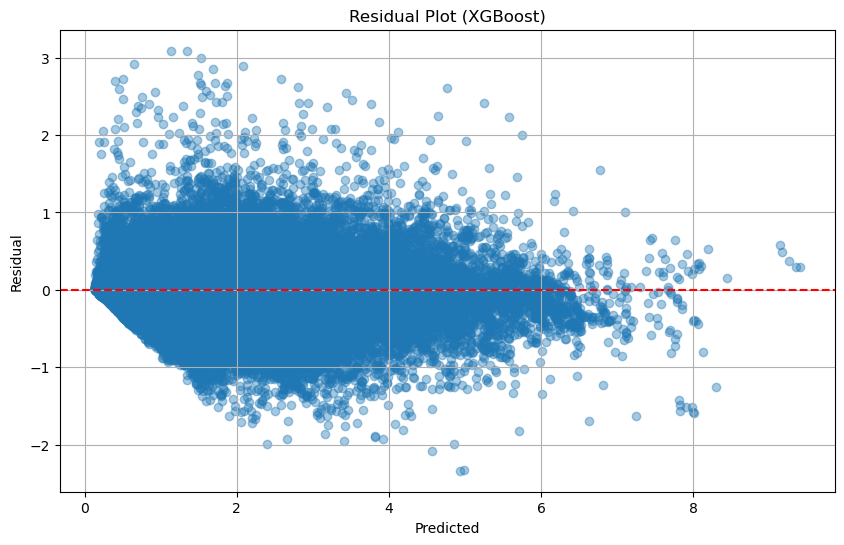

In [72]:
# ==========================================
# RESIDUAL PLOT
# ==========================================

residuals = y_test.values - xgb_predictions
plt.figure(figsize=(10,6))
plt.scatter(
    xgb_predictions,
    residuals,
    alpha=0.4
)
plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot (XGBoost)")
plt.grid(True)
plt.show()

In [74]:
comparison = pd.DataFrame({
"Model":[
"Random Forest",
"XGBoost"
],
"R2":[
r2,
xgb_r2
],
"RMSE":[
rmse,
xgb_rmse
],
"MAE":[
mae,
xgb_mae
],
"MAPE":[
mape,
xgb_mape
],
"Training Time":[
training_time,
xgb_training_time
]
})
comparison

,Model,R2,RMSE,MAE,MAPE,Training Time
0,Random Forest,0.967809,0.160835,0.059268,0.06431,549.285814
1,XGBoost,0.972050,0.149865,0.062009,0.06724,79.723036


In [77]:
joblib.dump(
xgb_model,
"xgboost_energy_forecasting.pkl"
)

['xgboost_energy_forecasting.pkl']

In [78]:
loaded_model = joblib.load(
"xgboost_energy_forecasting.pkl"
)

In [79]:
loaded_model.predict(X_test[:5])

array([1.5084927, 1.5074377, 1.5144204, 1.5547726, 1.5904471],
      dtype=float32)

In [80]:
print(y_test[:5])


1649765    1.504
1649766    1.510
1649767    1.514
1649768    1.566
1649769    1.584
Name: Global_active_power, dtype: float64


In [84]:
#========================================
#               Predict new Data
#========================================

samples = X_test.iloc[:10]
predictions = loaded_model.predict(samples)
pd.DataFrame({
"Actual":y_test.iloc[:10].values,
"Predicted":predictions
})

,Actual,Predicted
0,1.504,1.508493
1,1.510,1.507438
2,1.514,1.514420
3,1.566,1.554773
4,1.584,1.590447
5,1.592,1.611897
6,1.604,1.622911
7,1.582,1.630371
8,1.532,1.613456
9,1.476,1.535893
